# DeepLense Common Test I: a higher-resolution ResNet-18, compared with the baseline

**Problem found in notebook 02.** The baseline's main error is subhalo images predicted as "no substructure" (124 of 2,500 on the
test set). Subhalos are small clumps that change the arcs only slightly (notebook 01). The standard ResNet stem (7×7 stride-2 conv,
then a stride-2 max-pool) shrinks the 150×150 image to 38×38 before the first residual block. Such small details can be blurred away.

**Change.** Replace the stem with a **3×3 stride-1 conv** and keep the max-pool. The first residual block now works at **75×75**, twice
the resolution in each direction. Everything else stays identical to notebook 02: ImageNet initialisation, split, augmentation,
optimiser, schedule, 30 epochs and seed. Any difference therefore comes from the stem alone.

A fully stride-1 stem (150×150 in the first block) was also tried. It ran out of GPU memory at batch size 128 on the shared 16 GB GPU,
and would cost about 4× more time per epoch.

**Model choice is made on the validation set only.** The candidates are the baseline, the high-resolution model, and their average
(an ensemble). The candidate with the best validation macro AUC is the final model. All three are then scored on the test set once,
for transparency.

Shared code (batching, augmentation, model builder, training loop, prediction) lives in `src/deeplense_utils.py`. It is the same code
as notebook 02, moved into a module.

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import roc_auc_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay, classification_report

ROOT = Path("~/gsoc/eval-tests/ml4sci-deeplense").expanduser()
sys.path.insert(0, str(ROOT / "src"))
import deeplense_utils as U

SEED = 42
FIG, WEIGHTS, RUNS = ROOT / "report/figures", ROOT / "weights", ROOT / "runs"
torch.manual_seed(SEED); np.random.seed(SEED)
torch.backends.cudnn.benchmark = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
free, total = torch.cuda.mem_get_info()
print("device:", torch.cuda.get_device_name(0), f"| GPU memory free {free / 2**30:.1f} of {total / 2**30:.1f} GiB (shared GPU)")

d = U.load_common()
CLASSES, NAMES = d["meta"]["classes"], d["meta"]["class_names"]
MEAN, STD = d["meta"]["pixel_mean_trainfull"], d["meta"]["pixel_std_trainfull"]
y_val, y_test = d["y_all"][d["idx_valid"]], d["y_test"]
print(f"train {len(d['idx_train'])} | valid {len(d['idx_valid'])} | test {len(d['idx_test'])}")

device: NVIDIA RTX 2000 Ada Generation | GPU memory free 5.8 of 15.6 GiB (shared GPU)


train 27000 | valid 3000 | test 7500


## 1. The two models side by side

In [2]:
for stem in ["baseline", "hires"]:
    m = U.make_resnet18(stem).to(device)
    shapes = {}
    hooks = [getattr(m, n).register_forward_hook(lambda mod, i, o, n=n: shapes.__setitem__(n, tuple(o.shape[1:])))
             for n in ["maxpool", "layer1", "layer2", "layer3", "layer4"]]
    with torch.no_grad():
        m(torch.zeros(1, 1, 150, 150, device=device))
    for h in hooks: h.remove()
    print(f"{stem:8s} params {sum(p.numel() for p in m.parameters()) / 1e6:.2f} M | " +
          " | ".join(f"{k} {v[1]}x{v[2]}" for k, v in shapes.items()))
del m

baseline params 11.17 M | maxpool 38x38 | layer1 38x38 | layer2 19x19 | layer3 10x10 | layer4 5x5


hires    params 11.17 M | maxpool 75x75 | layer1 75x75 | layer2 38x38 | layer3 19x19 | layer4 10x10


## 2. Train the high-resolution model (same settings as notebook 02)

In [3]:
CFG = dict(epochs=30, batch_size=128, lr=1e-3, weight_decay=0.05, warmup_epochs=2, seed=SEED)
torch.manual_seed(SEED)
model = U.make_resnet18("hires").to(device).to(memory_format=torch.channels_last)
t0 = time.time()
history, best = U.train(model, d, CFG, device)
print(f"\ntraining time {(time.time() - t0) / 60:.1f} min | best valid AUC {best['auc']:.4f} at epoch {best['epoch']}")
torch.save({"state_dict": best["state"], "stem": "hires", "cfg": CFG, "epoch": best["epoch"], "valid_auc": best["auc"],
            "mean": MEAN, "std": STD}, WEIGHTS / "resnet18_hires_best.pt")
history.to_csv(RUNS / "resnet18_hires_history.csv", index=False)
_ = model.load_state_dict(best["state"])

epoch  1 | train loss 0.9438 | valid loss 0.7636 acc 0.7133 AUC 0.8941 | 91s


epoch  2 | train loss 0.4548 | valid loss 0.8339 acc 0.6383 AUC 0.9351 | 59s


epoch  3 | train loss 0.3535 | valid loss 0.5373 acc 0.7910 AUC 0.9512 | 45s


epoch  4 | train loss 0.2933 | valid loss 0.3408 acc 0.8760 AUC 0.9753 | 66s


epoch  5 | train loss 0.2608 | valid loss 0.3257 acc 0.8743 AUC 0.9764 | 77s


epoch  6 | train loss 0.2398 | valid loss 0.2104 acc 0.9257 AUC 0.9863 | 76s


... (20 outputs left out)

epoch 27 | train loss 0.0544 | valid loss 0.0842 acc 0.9723 AUC 0.9974 | 80s


epoch 28 | train loss 0.0496 | valid loss 0.0834 acc 0.9723 AUC 0.9975 | 80s


epoch 29 | train loss 0.0465 | valid loss 0.0837 acc 0.9730 AUC 0.9975 | 80s


epoch 30 | train loss 0.0475 | valid loss 0.0830 acc 0.9737 AUC 0.9976 | 80s

training time 38.8 min | best valid AUC 0.9976 at epoch 30


## 3. Learning curves: baseline (notebook 02) vs high-resolution

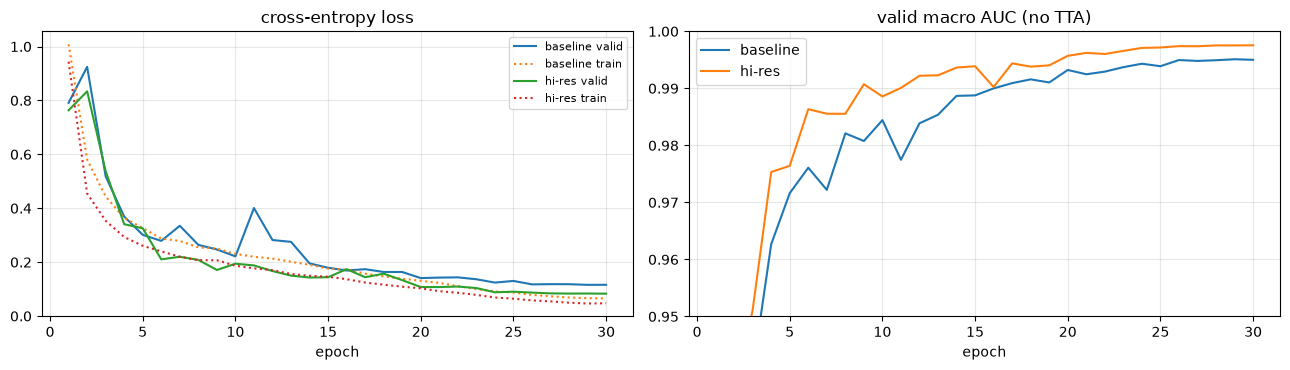

In [4]:
h_base = pd.read_csv(RUNS / "resnet18_baseline_history.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for h, name in [(h_base, "baseline"), (history, "hi-res")]:
    axes[0].plot(h.epoch, h.valid_loss, label=f"{name} valid"); axes[0].plot(h.epoch, h.train_loss, ls=":", label=f"{name} train")
    axes[1].plot(h.epoch, h.valid_auc, label=name)
axes[0].set_title("cross-entropy loss"); axes[0].legend(fontsize=8)
axes[1].set_title("valid macro AUC (no TTA)"); axes[1].set_ylim(0.95, 1.0); axes[1].legend()
for ax in axes: ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / "03_learning_curves_compare.png", bbox_inches="tight"); plt.show()

## 4. Choose the final model on the validation set
All candidates use 8-view test-time augmentation, which notebook 02 found helpful on validation. The table also shows the
high-resolution model without TTA, as a check.

In [5]:
ck = torch.load(WEIGHTS / "resnet18_baseline_best.pt", map_location=device, weights_only=False)
base = U.make_resnet18("baseline").to(device).to(memory_format=torch.channels_last)
_ = base.load_state_dict(ck["state_dict"])

def probs(m, X, idx, tta=True):
    return U.predict(m, X, idx, MEAN, STD, device, tta=tta)

pv = {"baseline": probs(base, d["X_all"], d["idx_valid"]), "hi-res": probs(model, d["X_all"], d["idx_valid"])}
pv["ensemble (mean)"] = (pv["baseline"] + pv["hi-res"]) / 2
pv_hires_plain = probs(model, d["X_all"], d["idx_valid"], tta=False)

sel = pd.DataFrame({k: {"valid macro AUC": U.macro_auc(y_val, p),
                        "valid subhalo-vs-rest AUC": roc_auc_score(y_val == 1, p[:, 1]),
                        "valid accuracy": (p.argmax(1) == y_val).mean()}
                    for k, p in pv.items()}).T.round(4)
display(sel)
print(f"hi-res without TTA: valid macro AUC {U.macro_auc(y_val, pv_hires_plain):.4f}")
FINAL = sel["valid macro AUC"].idxmax()
print("final model chosen on validation:", FINAL)

,valid macro AUC,valid subhalo-vs-rest AUC,valid accuracy
baseline,0.9967,0.9946,0.9677
hi-res,0.9981,0.9973,0.9780
ensemble (mean),0.9979,0.9968,0.9757


hi-res without TTA: valid macro AUC 0.9976
final model chosen on validation: hi-res


## 5. Held-out test set (used once)

In [6]:
pt = {"baseline": probs(base, d["X_test"], d["idx_test"]), "hi-res": probs(model, d["X_test"], d["idx_test"])}
pt["ensemble (mean)"] = (pt["baseline"] + pt["hi-res"]) / 2

def summary(p):
    r = {f"{NAMES[c]} vs rest": auc(*roc_curve(y_test == i, p[:, i])[:2]) for i, c in enumerate(CLASSES)}
    r["micro-average"] = auc(*roc_curve(np.eye(3)[y_test].ravel(), p.ravel())[:2])
    r["macro-average (OvR)"] = U.macro_auc(y_test, p)
    r["accuracy"] = (p.argmax(1) == y_test).mean()
    return r

test_table = pd.DataFrame({k: summary(p) for k, p in pt.items()}).round(4)
display(test_table)
errors = pd.DataFrame({k: {"subhalo predicted as no-sub": int(((y_test == 1) & (p.argmax(1) == 0)).sum()),
                           "all wrong predictions": int((p.argmax(1) != y_test).sum())} for k, p in pt.items()})
display(errors)
print(f"final model (chosen on validation): {FINAL}")

,baseline,hi-res,ensemble (mean)
no substructure vs rest,0.9962,0.9964,0.9966
subhalo (CDM) vs rest,0.9928,0.9945,0.9943
vortex vs rest,0.9985,0.9991,0.9990
micro-average,0.9969,0.9977,0.9976
macro-average (OvR),0.9958,0.9967,0.9966
accuracy,0.9680,0.9732,0.9731


,baseline,hi-res,ensemble (mean)
subhalo predicted as no-sub,124,103,109
all wrong predictions,240,201,202


final model (chosen on validation): hi-res


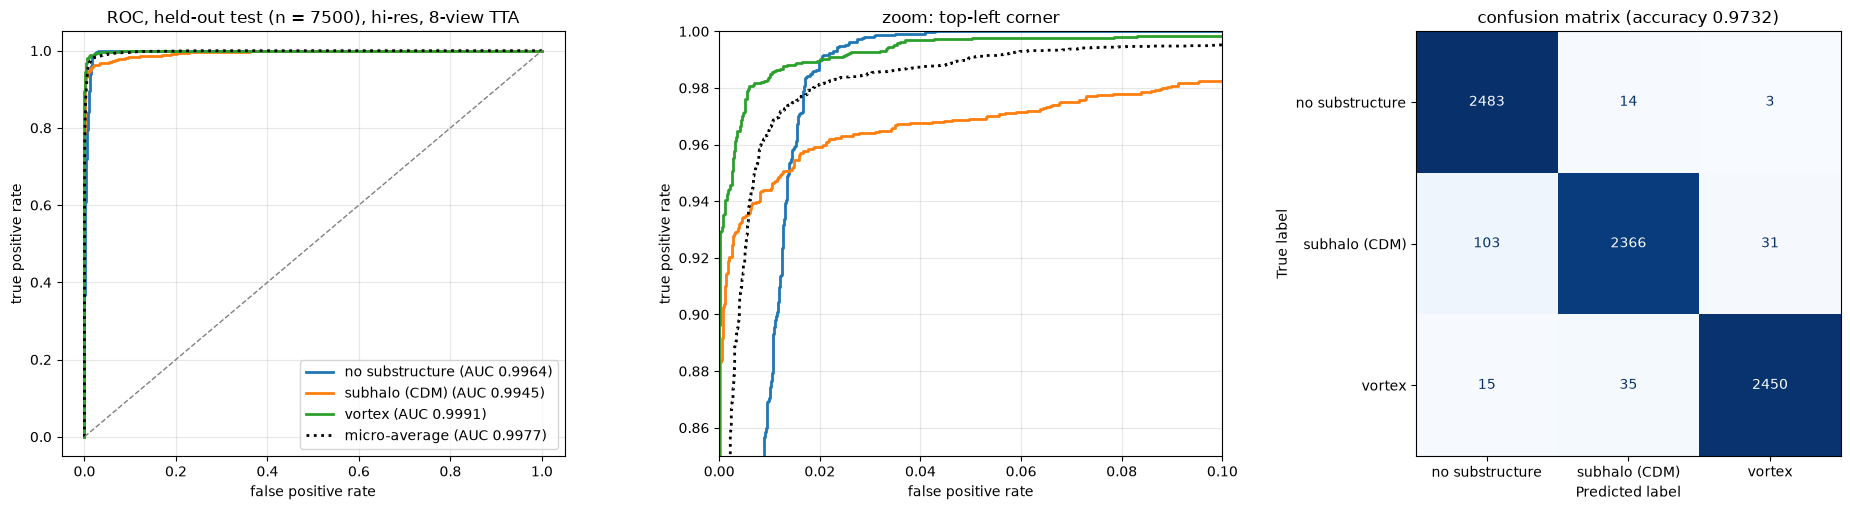

                 precision    recall  f1-score   support

no substructure     0.9546    0.9932    0.9735      2500
  subhalo (CDM)     0.9797    0.9464    0.9628      2500
         vortex     0.9863    0.9800    0.9831      2500

       accuracy                         0.9732      7500
      macro avg     0.9736    0.9732    0.9731      7500
   weighted avg     0.9736    0.9732    0.9731      7500



In [7]:
p = pt[FINAL]; pred = p.argmax(1)
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
for ax, zoom in zip(axes[:2], [False, True]):
    for i, cls in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(y_test == i, p[:, i])
        ax.plot(fpr, tpr, lw=2, label=f"{NAMES[cls]} (AUC {auc(fpr, tpr):.4f})")
    fpr, tpr, _ = roc_curve(np.eye(3)[y_test].ravel(), p.ravel())
    ax.plot(fpr, tpr, ls=":", c="k", lw=2, label=f"micro-average (AUC {auc(fpr, tpr):.4f})")
    ax.plot([0, 1], [0, 1], c="grey", lw=1, ls="--")
    ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.grid(alpha=0.3)
    if zoom:
        ax.set_xlim(0, 0.1); ax.set_ylim(0.85, 1.0); ax.set_title("zoom: top-left corner")
    else:
        ax.set_title(f"ROC, held-out test (n = {len(y_test)}), {FINAL}, 8-view TTA"); ax.legend(loc="lower right")
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=[NAMES[c] for c in CLASSES]).plot(ax=axes[2], cmap="Blues", colorbar=False)
axes[2].set_title(f"confusion matrix (accuracy {(pred == y_test).mean():.4f})")
fig.tight_layout(); fig.savefig(FIG / "03_roc_confusion_test_final.png", bbox_inches="tight"); plt.show()
print(classification_report(y_test, pred, target_names=[NAMES[c] for c in CLASSES], digits=4))

_ = (ROOT / "report/results_03_compare.json").write_text(json.dumps({
    "final_model": FINAL, "selection_on_valid": sel.to_dict(), "test": test_table.to_dict(), "test_errors": errors.to_dict(),
    "hires_cfg": CFG, "hires_best_epoch": best["epoch"]}, indent=2, default=float))

## 6. Notes

**Result.** The **high-resolution ResNet-18 is the final model.** It had the best validation macro AUC (0.9981, vs 0.9967 for the
baseline and 0.9979 for the ensemble), so it was chosen before the test set was used.

| Held-out test (7,500 images, 8-view TTA) | baseline (nb 02) | **hi-res (final)** | ensemble |
|---|---|---|---|
| no substructure vs rest AUC | 0.9962 | **0.9964** | 0.9966 |
| subhalo (CDM) vs rest AUC | 0.9928 | **0.9945** | 0.9943 |
| vortex vs rest AUC | 0.9985 | **0.9991** | 0.9990 |
| micro-average AUC | 0.9969 | **0.9977** | 0.9976 |
| **macro-average AUC** | 0.9958 | **0.9967** | 0.9966 |
| accuracy | 0.9680 | **0.9732** | 0.9731 |
| wrong predictions | 240 | **201** | 202 |
| subhalo predicted as "no substructure" | 124 | **103** | 109 |

**Is the gain real? Yes.** The check is in `src/compare_significance.py`; its output is in `report/significance_03.json`.
- **McNemar test** on the images where exactly one model is right: hi-res is right on 80 that the baseline gets wrong, and the baseline
  on 41 that hi-res gets wrong. Exact p-value = 0.0005.
- **Paired bootstrap** (2,000 resamples of the test set): macro AUC improves by +0.0009, 95 % CI [+0.0003, +0.0013]. Hi-res is better
  in 99.95 % of the resamples.

**Interpretation.**
- **The change hit the intended weakness.** Keeping 2× more spatial detail in the first block reduced errors by 16 %, and the largest
  gain is on the subhalo class (AUC 0.9928 → 0.9945). Subhalo clumps are the smallest, faintest signal, which is exactly what early
  down-sampling would blur.
- **The ensemble doesn't help.** The baseline adds no information that the hi-res model lacks.
- **Subhalo → "no substructure" is still the main error** (103 of 2,500). The zoomed ROC shows the subhalo curve as the lowest. These
  are probably images where the clumps sit far from the arcs, so they barely change the image. Looking at the misclassified images
  would test this idea.
- **Cost:** about 3× slower per epoch (about 80 s vs 25 s on the shared GPU), with the same 11.2 M parameters.
- **Validation AUC was still rising at epoch 30** (best = last epoch), so a longer schedule could add a little more.

**What I would try next:**
1. A fully stride-1 stem (150×150 in the first block), on a free GPU or with gradient accumulation.
2. 50 epochs.
3. Look at the 103 missed subhalo images.
4. A physics-informed variant (Specific Test VII) that uses the lensing equation.